# RC3SI — Stage 01: Understand and audit the original 2023 tomato IoT dataset

**Run on Google Colab, top-to-bottom.** One task per code cell. There is no training or simulated data in this notebook.

**Dataset:** Belli et al., *IoT-based Dataset of a Tomato Cultivation Under Different Irrigation Regimes*, Mendeley Data v2, DOI https://doi.org/10.17632/35wh56287y.2, CC BY 4.0.

Use `RC3SI_Parma2023_Raw_Data_Only_v1.zip`, which contains README plus 4 CSVs copied without modification from the *raw-data subfolder* of your uploaded Work-mode archive. Ideally compare raw checksums against a fresh authoritative Mendeley download before using in published research. We independently audit data below. **No model results are accepted from the prior Work-mode ZIP.**

**Goal:** inspect data, identify sensor mappings, clean repeated header rows, check missingness, and visualize real observations.

**Ground-truth limitation:** lines 1/2/3 correspond to irrigation *treatments* 100/60/30%; these are not clinically/agronomically validated time-resolved plant-stress classes.

## 1. Import libraries

In [1]:
from pathlib import Path
import io, zipfile, hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
print('Pandas:', pd.__version__)

Pandas: 2.2.3


## 2. Upload the small raw-data ZIP to Colab
In the upload dialog select the supplied `RC3SI_Parma2023_Raw_Data_Only_v1.zip`. This is a small raw-data-only archive, **not** the 28.3 GB research dataset.

In [2]:
from google.colab import files
uploaded = files.upload()
assert len(uploaded) == 1, 'Please upload exactly one dataset ZIP'
zip_name, zip_bytes = next(iter(uploaded.items()))
assert zip_name.lower().endswith('.zip'), 'Expected .zip file'
print('Uploaded:', zip_name, 'bytes:', len(zip_bytes))

Saving RC3SI_Parma2023_Raw_Data_Only_v1.zip to RC3SI_Parma2023_Raw_Data_Only_v1.zip
Uploaded: RC3SI_Parma2023_Raw_Data_Only_v1.zip bytes: 920149


## 3. Inspect ZIP inventory without changing raw files

In [3]:
with zipfile.ZipFile(io.BytesIO(zip_bytes)) as zf:
    members = [info for info in zf.infolist() if not info.is_dir()]
    for info in members:
        print(f'{info.file_size:>10,} bytes  {info.filename}')
    assert any(info.filename.endswith('README.TXT') for info in members), 'README missing'
    assert sum(info.filename.endswith('.csv') for info in members) == 4, 'Expected exactly 4 CSV files'

     1,004 bytes  parma2023_raw/ATTRIBUTION_AND_PROVENANCE.md
     2,147 bytes  parma2023_raw/README.TXT
       435 bytes  parma2023_raw/SHA256SUMS.txt
     4,336 bytes  parma2023_raw/indicators.csv
 1,206,822 bytes  parma2023_raw/stuard_environmental_data.csv
 3,500,782 bytes  parma2023_raw/stuard_soil_data.csv
 3,038,311 bytes  parma2023_raw/stuard_water_meter_data.csv


## 4. Load README and original CSV bytes in memory
This avoids accidental changes to the files and keeps the upstream raw source intact.

In [4]:
with zipfile.ZipFile(io.BytesIO(zip_bytes)) as zf:
    file_bytes = {Path(info.filename).name: zf.read(info.filename)
                  for info in zf.infolist() if not info.is_dir()}
print('Original files:', sorted(file_bytes))
print('\nREADME:\n')
print(file_bytes['README.TXT'].decode('utf-8', errors='replace'))

Original files: ['ATTRIBUTION_AND_PROVENANCE.md', 'README.TXT', 'SHA256SUMS.txt', 'indicators.csv', 'stuard_environmental_data.csv', 'stuard_soil_data.csv', 'stuard_water_meter_data.csv']

README:

The dataset is composed by 4 CSV files: 

“stuard_environmental_data.csv”: contains the data generated by a Milesight EM500 CO2 device, namely, timestamp (ms), device identifier, air moisture (%RH), air temperature (◦C), CO2 level (ppm), barometric pressure (hPa), and battery (%). The geographic coordinates of the device are (lat: 44.809362, lon:10.273168). The data are sampled every 10 minutes. 

“stuard_water_meter_data.csv”: contains the data generated by three Talkpool OY1310 Water Meter devices, one per tomato line. This CSV file contains timestamp (ms), device identifier, line (number), and water volume (m3). The geographic coordinates of these devices are (lat: 44.808673, lon: 10.272948) for Line #1, (lat: 44.808669, lon: 10.272988) for Line #2, (lat: 44.808667, lon: 10.273026) for Li

## 5. Read the four CSV files

In [5]:
raw = {
  'environment': pd.read_csv(io.BytesIO(file_bytes['stuard_environmental_data.csv']), low_memory=False),
  'soil': pd.read_csv(io.BytesIO(file_bytes['stuard_soil_data.csv']), low_memory=False),
  'water': pd.read_csv(io.BytesIO(file_bytes['stuard_water_meter_data.csv']), low_memory=False),
  'indicators': pd.read_csv(io.BytesIO(file_bytes['indicators.csv']), low_memory=False),
}
for name, df in raw.items():
    print(name, 'shape:', df.shape)

environment shape: (10964, 8)
soil shape: (32668, 8)
water shape: (32649, 5)
indicators shape: (77, 8)


## 6. Inspect column names, types and example records

In [6]:
for name, df in raw.items():
    print('\n###', name)
    print('Columns:', list(df.columns))
    display(df.head(3))


### environment
Columns: ['id', 'device_identifier', 'ts_generation', 'co2', 'humidity', 'pressure', 'temperature', 'battery']


,id,device_identifier,ts_generation,co2,humidity,pressure,temperature,battery
0,31938,abc0d16aaf15b3a4ee2e561195dfd82ab260497412e326...,1688019286484,635,61.0,1010.7,24.5,NaN
1,32234,abc0d16aaf15b3a4ee2e561195dfd82ab260497412e326...,1688043749456,472,39.5,1010.9,41.2,100.0
2,32243,abc0d16aaf15b3a4ee2e561195dfd82ab260497412e326...,1688044308221,467,46.0,1010.8,40.2,NaN



### soil
Columns: ['id', 'ts_generation', 'device_identifier', 'line', 'electrical_conductivity', 'humidity', 'temperature', 'battery']


,id,ts_generation,device_identifier,line,electrical_conductivity,humidity,temperature,battery
0,32299,1688047456101,9d5fe860849cee394ff52cd69a6d69642ea9f4756dac17...,2,723,31.9,29.1,NaN
1,32309,1688048057491,9d5fe860849cee394ff52cd69a6d69642ea9f4756dac17...,2,723,31.9,29,NaN
2,32319,1688048658856,9d5fe860849cee394ff52cd69a6d69642ea9f4756dac17...,2,723,31.74,29,NaN



### water
Columns: ['id', 'ts_generation', 'device_identifier', 'line', 'current_volume']


,id,ts_generation,device_identifier,line,current_volume
0,31605,1687990762714,b11e71f8660d9d4afc220110d60e8856c38b6af3613b3e...,1,0
1,31612,1687991363563,b11e71f8660d9d4afc220110d60e8856c38b6af3613b3e...,1,0
2,31619,1687991963512,b11e71f8660d9d4afc220110d60e8856c38b6af3613b3e...,1,0



### indicators
Columns: ['Unnamed: 0', 'gdd', 'standard_day_degree', 'daily_mean_temperature', 'daily_max_above_Tbase', 'daily_max', 'daily_max_reduction', 'ontario_units']


,Unnamed: 0,gdd,standard_day_degree,daily_mean_temperature,daily_max_above_Tbase,daily_max,daily_max_reduction,ontario_units
0,1.687990e+12,13.0,22.20,32.20,31.2,41.2,12.8,27.984
1,1.688076e+12,21.3,12.95,22.95,17.6,27.6,17.6,28.804
2,1.688162e+12,31.2,15.05,25.05,23.2,33.2,20.8,27.272


## 7. Detect unexpected repeated CSV headers
A repeated header is a row of text that looks like column names; it is **not** a real sensor measurement.

In [7]:
for name in ('environment', 'soil', 'water'):
    df = raw[name]
    parsed_ts = pd.to_numeric(df['ts_generation'], errors='coerce')
    invalid = parsed_ts.isna()
    print(f'{name}: {invalid.sum()} invalid timestamp rows (possible repeated headers)')
    if invalid.any():
        display(df.loc[invalid].head())

environment: 0 invalid timestamp rows (possible repeated headers)
soil: 2 invalid timestamp rows (possible repeated headers)


,id,ts_generation,device_identifier,line,electrical_conductivity,humidity,temperature,battery
10862,id,ts_generation,device_identifier,line,electrical_conductivity,humidity,temperature,battery
21701,id,ts_generation,device_identifier,line,electrical_conductivity,humidity,temperature,battery


water: 2 invalid timestamp rows (possible repeated headers)


,id,ts_generation,device_identifier,line,current_volume
10800,id,ts_generation,device_identifier,line,current_volume
21707,id,ts_generation,device_identifier,line,current_volume


## 8. Clean timestamps and repeated header rows
Only remove invalid timestamp/header rows from the sensor CSVs. **Do not fabricate missing sensor readings.** Keep source data unchanged in the uploaded ZIP.

In [8]:
clean = {}
for name in ('environment', 'soil', 'water'):
    df = raw[name].copy()
    valid = pd.to_numeric(df['ts_generation'], errors='coerce').notna()
    df = df.loc[valid].copy()
    df['timestamp'] = pd.to_datetime(pd.to_numeric(df['ts_generation']), unit='ms', utc=True, errors='raise')
    if 'line' in df:
        df['line'] = pd.to_numeric(df['line'], errors='raise').astype(int)
    clean[name] = df.sort_values('timestamp').reset_index(drop=True)
    print(name, 'clean rows:', len(df), 'removed header/invalid timestamp rows:', (~valid).sum())

environment clean rows: 10964 removed header/invalid timestamp rows: 0
soil clean rows: 32666 removed header/invalid timestamp rows: 2
water clean rows: 32647 removed header/invalid timestamp rows: 2


## 9. Verify timestamps and observation coverage

In [9]:
for name, df in clean.items():
    print(f'{name:12s} {len(df):>6,} observations  {df.timestamp.min()}  to  {df.timestamp.max()}')

environment  10,964 observations  2023-06-29 06:14:46.484000+00:00  to  2023-09-13 21:51:25.121000+00:00
soil         32,666 observations  2023-06-28 22:09:25.881000+00:00  to  2023-09-13 21:59:05.445000+00:00
water        32,647 observations  2023-06-28 22:00:13.150000+00:00  to  2023-09-13 21:58:42.469000+00:00


## 10. Verify source device-to-line mappings
**Important:** the environmental file has one device and no `line` column; that means shared environmental context, not one air sensor per tomato line.

In [10]:
print('Environmental device IDs:', clean['environment']['device_identifier'].unique())
print('Environmental has line column?', 'line' in clean['environment'].columns)
for name in ['soil', 'water']:
    print('\n', name, 'device -> line pairs:')
    display(clean[name][['device_identifier','line']].drop_duplicates().sort_values('line'))

Environmental device IDs: ['abc0d16aaf15b3a4ee2e561195dfd82ab260497412e326bb57f2ee5bbe9042d8']
Environmental has line column? False

 soil device -> line pairs:


,device_identifier,line
0,91738f0250e567c5c673d2217596991d2eec0cc6da56ca...,1
96,9d5fe860849cee394ff52cd69a6d69642ea9f4756dac17...,2
120,0fa420b6626076658c3c1763550aee8149c2be5dba876a...,3



 water device -> line pairs:


,device_identifier,line
4,b11e71f8660d9d4afc220110d60e8856c38b6af3613b3e...,1
0,d17de8bc7da9be6528f0b5eb2a108138d2b885433890da...,2
1,c733ec31aff4605215b6a5fba926aaae8cf58133bb1f6d...,3


## 11. Add treatment metadata for the audit only
The treatment mapping must never be passed directly to a classifier as an input feature.

In [11]:
treatment_percent = {1: 100, 2: 60, 3: 30}
print('2023 irrigation treatment mapping (Irriframe percentages):', treatment_percent)
print('WARNING: these are regime labels, not independently measured plant-stress diagnoses.')

2023 irrigation treatment mapping (Irriframe percentages): {1: 100, 2: 60, 3: 30}


## 12. Measure missingness
Preserve NaNs so subsequent imputation can be fit on **training data only**.

In [12]:
missingness = []
for name, df in clean.items():
    for col, frac in df.isna().mean().items():
        missingness.append({'table':name, 'column':col, 'missing_percent':round(100*frac,3)})
missing_df = pd.DataFrame(missingness).sort_values(['table','missing_percent'],ascending=[True,False])
display(missing_df)

,table,column,missing_percent
7,environment,battery,99.316
0,environment,id,0.000
1,environment,device_identifier,0.000
2,environment,ts_generation,0.000
3,environment,co2,0.000
4,environment,humidity,0.000
5,environment,pressure,0.000
6,environment,temperature,0.000
8,environment,timestamp,0.000
16,soil,battery,99.308


## 13. Draw recorded soil-moisture trajectories for the three treatment lines
The original dataset labels the soil moisture column `humidity` and the documentation labels its unit `%RH`; retain this documented label for now, without silently converting units.

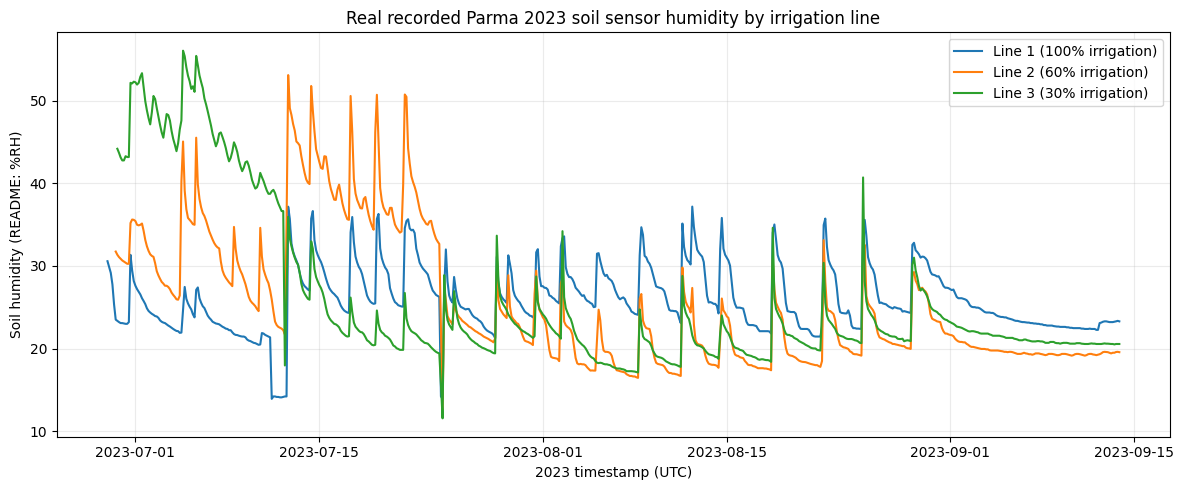

In [13]:
df = clean['soil'].copy()
df['humidity'] = pd.to_numeric(df['humidity'],errors='coerce')
fig, ax = plt.subplots(figsize=(12,5))
for line, group in df.groupby('line'):
    series = group.set_index('timestamp')['humidity'].resample('3h').median()
    ax.plot(series.index,series.values,label=f'Line {line} ({treatment_percent[line]}% irrigation)')
ax.set_title('Real recorded Parma 2023 soil sensor humidity by irrigation line')
ax.set_xlabel('2023 timestamp (UTC)')
ax.set_ylabel('Soil humidity (README: %RH)')
ax.legend()
ax.grid(alpha=.25)
plt.tight_layout()
plt.show()

## 14. Export your first audit as evidence
Download only the audit CSV (no model scores). The screenshot of the plot and the cell outputs complete Stage 01.

In [14]:
summary = pd.DataFrame([
  {'table':name, 'rows_after_header_cleaning':len(df),
   'first_timestamp_utc':str(df.timestamp.min()),'last_timestamp_utc':str(df.timestamp.max()),
   'unique_devices':df.device_identifier.nunique()}
  for name,df in clean.items()
])
summary.to_csv('RC3SI_stage01_data_inventory.csv',index=False)
missing_df.to_csv('RC3SI_stage01_missingness.csv',index=False)
display(summary)
print('Saved audit CSVs. Use Colab file browser to download them if needed.')

,table,rows_after_header_cleaning,first_timestamp_utc,last_timestamp_utc,unique_devices
0,environment,10964,2023-06-29 06:14:46.484000+00:00,2023-09-13 21:51:25.121000+00:00,1
1,soil,32666,2023-06-28 22:09:25.881000+00:00,2023-09-13 21:59:05.445000+00:00,3
2,water,32647,2023-06-28 22:00:13.150000+00:00,2023-09-13 21:58:42.469000+00:00,3


Saved audit CSVs. Use Colab file browser to download them if needed.


## Stop here and review before moving to Stage 02
Send the outputs of cells **7, 9, 10 and 14**, plus any errors, to ChatGPT. We'll verify the sensor mapping and decide feature preprocessing and the **chronological** split next.

Note: 2023 alone permits a classroom implementation and an *honest within-season* benchmark, but cannot establish independently replicated treatment effects, true external generalization, physiological stress, early warning, or patentability.